# 1. Delinquency transitions and portfolio analytics

How do loans move between payment statuses, and how well does a Markov chain describe that?
Run `python -m repo_risk.cli run-all` from the repository root first.

The portfolio is synthetic. Nothing here describes a real lender.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from autoloan_sim import load_portfolio
from repo_risk import analytics as an
from repo_risk import transitions as tr
from repo_risk.cli import load_config

pd.options.display.float_format = "{:.4f}".format
cfg = load_config("configs/default.yaml")
p = load_portfolio("data/raw")
pairs = tr.transition_pairs(p.monthly)
matrix = tr.transition_matrix(pairs)
print(f"{len(p.loans):,} loans, {len(pairs):,} month-to-month transitions")

30,000 loans, 915,951 month-to-month transitions


## Three different things: delinquency, default, repossession

* **Delinquency** is a status. The account is some number of days past due this month.
* **Default** is a definition I chose: the first time a loan is 120+ days past due, or is repossessed or charged off.
* **Repossession** is something the servicer does. It needs a delinquent borrower, and also a decision
  to assign the account, capacity to work it, and a vehicle that can be found.

The counts show they are not the same set of loans.

In [2]:
o = p.outcomes
ever60 = p.monthly.loc[p.monthly.days_past_due >= 60, "loan_id"].nunique()
pd.Series({
    "loans": len(o),
    "ever 60+ days past due": ever60,
    "defaulted (120+ DPD, repossessed or charged off)": o.default_date.notna().sum(),
    "repossessed": (o.final_status == "repossessed").sum(),
    "  of which voluntary surrender": o.voluntary_surrender.sum(),
    "charged off without repossession": (o.final_status == "charged_off").sum(),
    "defaulted but later paid off or still open": (o.default_date.notna() & o.final_status.isin(["paid_off", "active"])).sum(),
    "still open at the data cutoff (censored)": o.censored.sum(),
}).to_frame("count")

,count
loans,30000
ever 60+ days past due,7473
"defaulted (120+ DPD, repossessed or charged off)",4165
repossessed,2728
of which voluntary surrender,295
charged off without repossession,969
defaulted but later paid off or still open,468
still open at the data cutoff (censored),17059


## The transition matrix

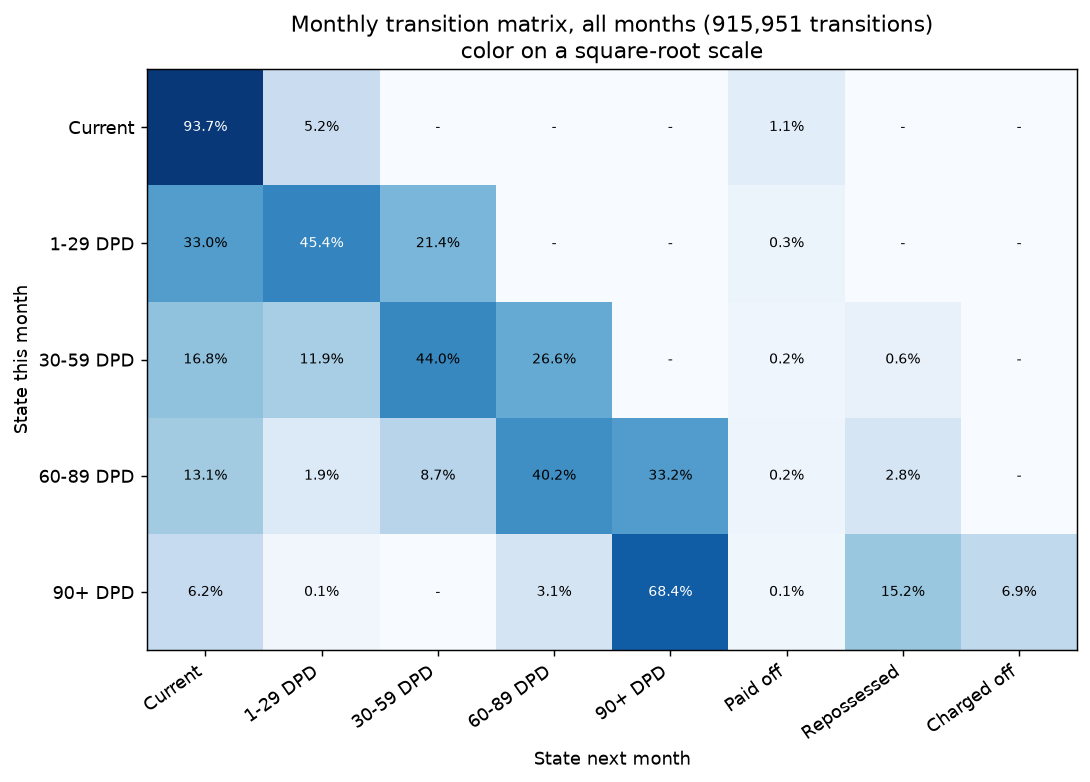

,cure_to_current,improve,stay,roll_forward,paid_off,repossessed,charged_off
state,,,,,,,
Current,NaN,0.0000,0.9366,0.0521,0.0113,0.0000,0.0000
1-29 DPD,0.3296,0.3296,0.4536,0.2142,0.0026,0.0000,0.0000
30-59 DPD,0.1678,0.2866,0.4395,0.2662,0.0021,0.0056,0.0000
60-89 DPD,0.1307,0.2362,0.4015,0.3323,0.0024,0.0276,0.0000
90+ DPD,0.0623,0.0943,0.6839,0.0000,0.0013,0.1519,0.0685


In [3]:
display(Image("figures/transition_matrix.png"))
tr.roll_rates(matrix).rename(index=tr.STATE_LABELS)

Reading one row: of the accounts that are 30-59 days past due this month, about 44% are still there
next month, about 27% roll to 60-89, and about 29% improve. Direct repossession from 30-59 is rare
(voluntary surrenders only).

## What the chain implies, and where that goes wrong

In [4]:
implied = tr.eventual_absorption(matrix).rename(index=tr.STATE_LABELS, columns=tr.STATE_LABELS)
implied["Repossessed within 12 months"] = tr.horizon_probability(matrix, "repossessed", 12).loc[tr.OPEN_STATES].to_numpy()
implied

,Paid off,Repossessed,Charged off,Repossessed within 12 months
Current,0.6793,0.2356,0.0852,0.0144
1-29 DPD,0.6096,0.2867,0.1036,0.0726
30-59 DPD,0.4977,0.3690,0.1334,0.1863
60-89 DPD,0.3397,0.4793,0.1809,0.3520
90+ DPD,0.1734,0.5750,0.2517,0.5077


In [5]:
seasoned = p.outcomes.merge(p.loans[["loan_id", "origination_date"]])
seasoned = seasoned[seasoned.origination_date.dt.year == 2019]
print("2019 originations, actual outcomes so far:")
print(seasoned.final_status.value_counts(normalize=True).round(3).to_string())

2019 originations, actual outcomes so far:
final_status
paid_off      0.6300
active        0.2010
repossessed   0.1210
charged_off   0.0480


The chain says a current loan eventually ends in repossession about 24% of the time. The 2019 loans
are at 12% so far, with a fifth of them still open. The chain has no idea that loans
amortize and mature. It lets an account wander between states forever, so it has far too many
chances to go bad. The 12-month numbers are much closer to reality than the "eventual" ones.

## Projection against what happened
Take every loan open at the end of June 2023, estimate the matrix from earlier months only, project 12 months.

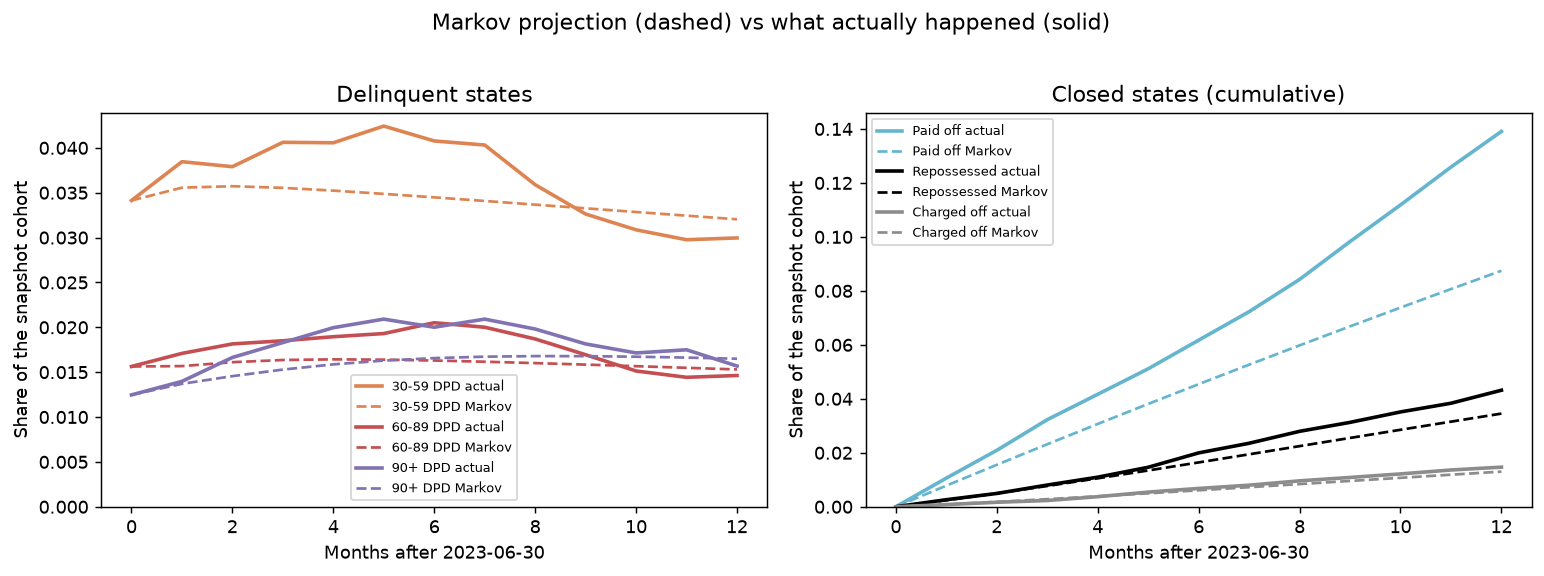

,actual,markov,error
Current,0.6675,0.7238,0.0564
1-29 DPD,0.0753,0.0773,0.0020
30-59 DPD,0.0300,0.0320,0.0021
60-89 DPD,0.0146,0.0153,0.0007
90+ DPD,0.0157,0.0165,0.0008
Paid off,0.1391,0.0875,-0.0516
Repossessed,0.0432,0.0345,-0.0087
Charged off,0.0147,0.0130,-0.0017


In [6]:
display(Image("figures/markov_projection_vs_actual.png"))
snap = pd.Timestamp("2023-06-30")
actual = tr.actual_distribution(p.monthly, snap, 12)
proj = tr.project(tr.transition_matrix(pairs[pairs.as_of_date < snap]), actual.iloc[0], 12)
comp = pd.DataFrame({"actual": actual.iloc[-1], "markov": proj.iloc[-1]}).rename(index=tr.STATE_LABELS)
comp["error"] = comp.markov - comp.actual
comp

The delinquent buckets come out close. The closed states do not: the chain projects too few payoffs
and too few repossessions. Payoffs are the bigger miss. Payoff gets more likely as a loan ages, and by
mid-2023 the book was older than the average month in the history used to estimate the matrix.

## Assumption 1: the same probabilities every month

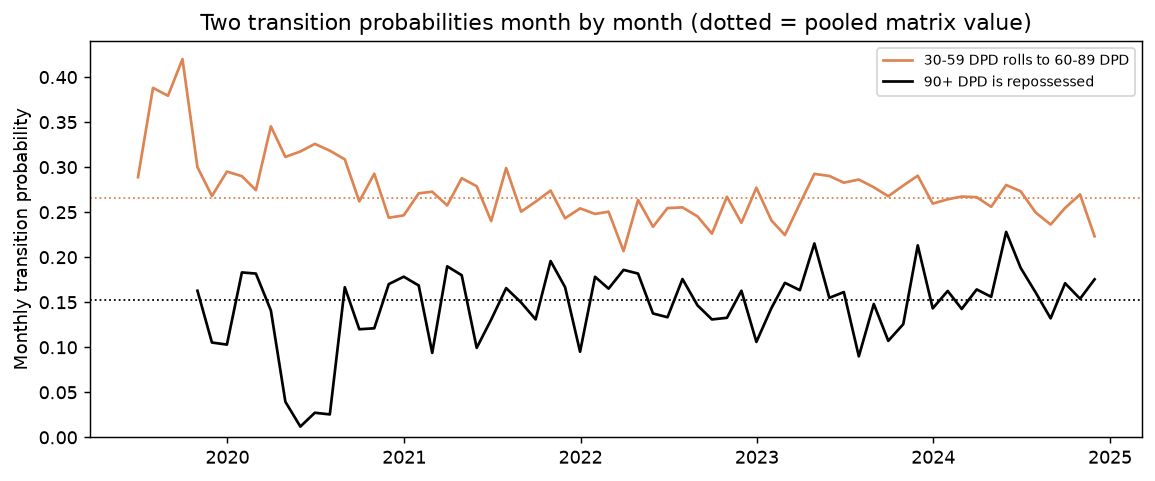

,Current,1-29 DPD,60-89 DPD,90+ DPD,Paid off,Repossessed,Charged off
after_2020,0.0650,0.0015,0.0331,0.6810,0.0002,0.1502,0.0691
before_pause,0.0639,0.0068,0.0274,0.7146,0.0000,0.1416,0.0457
recent,0.0607,0.0008,0.0297,0.6789,0.0021,0.1598,0.0679
servicing_pause,0.0567,0.0000,0.0232,0.7938,0.0000,0.0258,0.1005


In [7]:
display(Image("figures/transition_stability.png"))
checks = tr.markov_checks(pairs, {k: tuple(v) for k, v in cfg["analytics"]["periods"].items()})
pd.DataFrame(checks["time_homogeneity"]["dpd_90_plus"]["probs_by_period"]).T.rename(columns=tr.STATE_LABELS)

During the simulated servicing pause in 2020 the chance that a 90+ account was repossessed in a given
month fell from about 15% to under 3%, and more accounts sat at 90+ or were charged off instead.
Borrowers did not change. The servicer did. A matrix estimated across that period blends two regimes.

## Assumption 2: history does not matter

In [8]:
rows = []
for state, c in checks["memory"].items():
    for hist, v in c["improve_rate_by_history"].items():
        rows.append({"state now": tr.STATE_LABELS[state], "last month": hist, "improve next month": v,
                     "roll forward next month": c["roll_forward_rate_by_history"].get(hist, 0.0)})
pd.DataFrame(rows).set_index(["state now", "last month"])

improve next month  roll forward next month
state now last month                                                        
1-29 DPD  came back from worse               0.3540                   0.1774
          rolled in from better              0.3423                   0.2309
          stayed                             0.3114                   0.1996
30-59 DPD came back from worse               0.3423                   0.1455
          rolled in from better              0.2654                   0.3104
          stayed                             0.3079                   0.2220
60-89 DPD came back from worse               0.2844                   0.1562
          rolled in from better              0.2043                   0.3978
          stayed                             0.2799                   0.2484

It does matter. Among accounts at 60-89 days past due, those that just rolled in from a better bucket
roll forward again about 40% of the time. Those that came back from 90+ roll forward about 16% of the
time. The first group is on the way down, the second is recovering, and a first-order chain treats
them as the same.

## Vintage curves

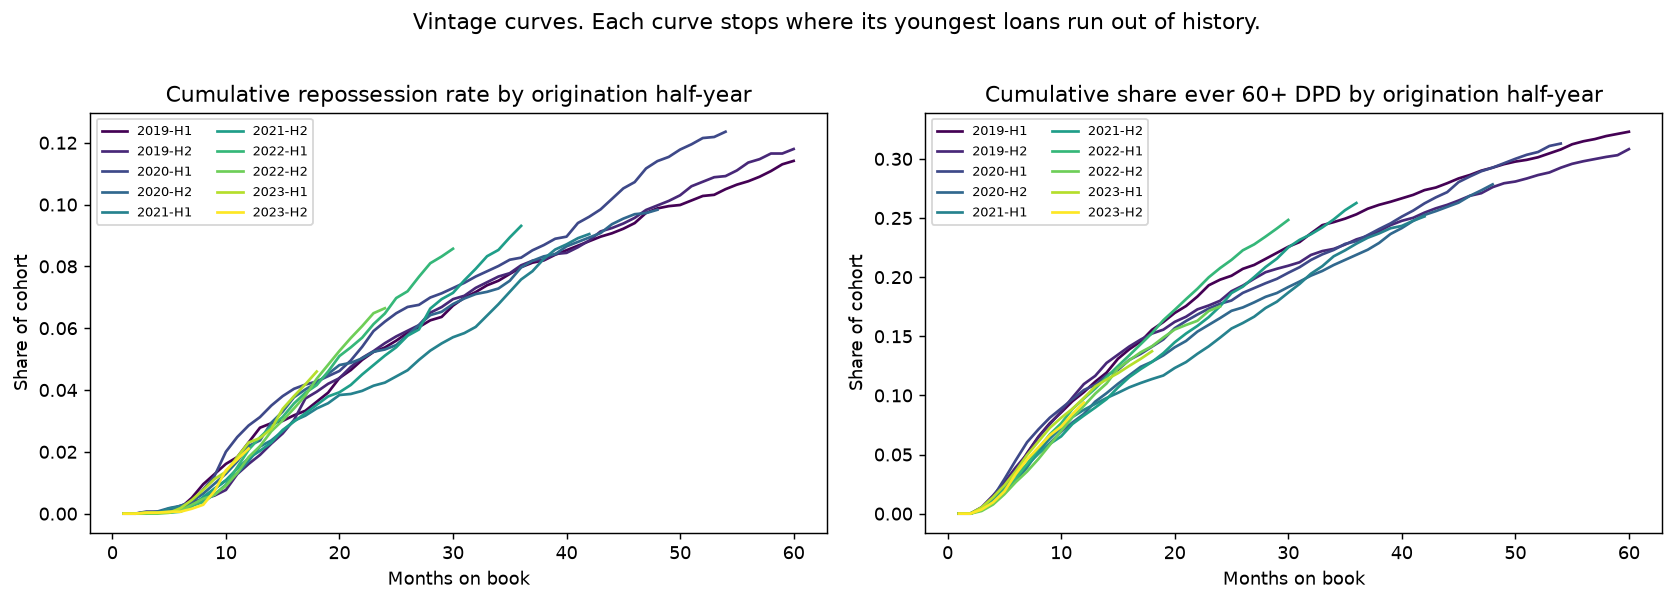

,loans,observed_through_mob,repo_by_mob_12,repo_by_mob_24,repo_by_mob_36,ever_60dpd_by_mob_12
cohort,,,,,,
2019-H1,2734,60,0.0230,0.0538,0.0797,0.1028
2019-H2,2738,60,0.0161,0.0551,0.0804,0.1096
2020-H1,2946,54,0.0285,0.0621,0.0828,0.1045
2020-H2,2787,48,0.0219,0.0531,0.0797,0.0843
2021-H1,2996,42,0.0170,0.0424,0.0758,0.0878
2021-H2,2954,36,0.0179,0.0511,0.0931,0.0829
2022-H1,3197,30,0.0206,0.0647,NaN,0.0973
2022-H2,3115,24,0.0183,0.0665,NaN,0.0912
2023-H1,3393,18,0.0230,NaN,NaN,0.0978


In [9]:
display(Image("figures/vintage_curves.png"))
an.cohort_summary(an.loan_event_ages(p), p.config.data_cutoff)

Each curve stops where its youngest loans run out of history. Without that rule the right end of
every curve would flatten, because loans that have not reached that age yet cannot have been
repossessed at that age. At 24 months on book the two 2022 cohorts have the highest repossession
rates, and 2021-H2 is the highest at 36 months. That matches the looser underwriting built into the
simulator for mid-2021 to mid-2022.

## Months on book

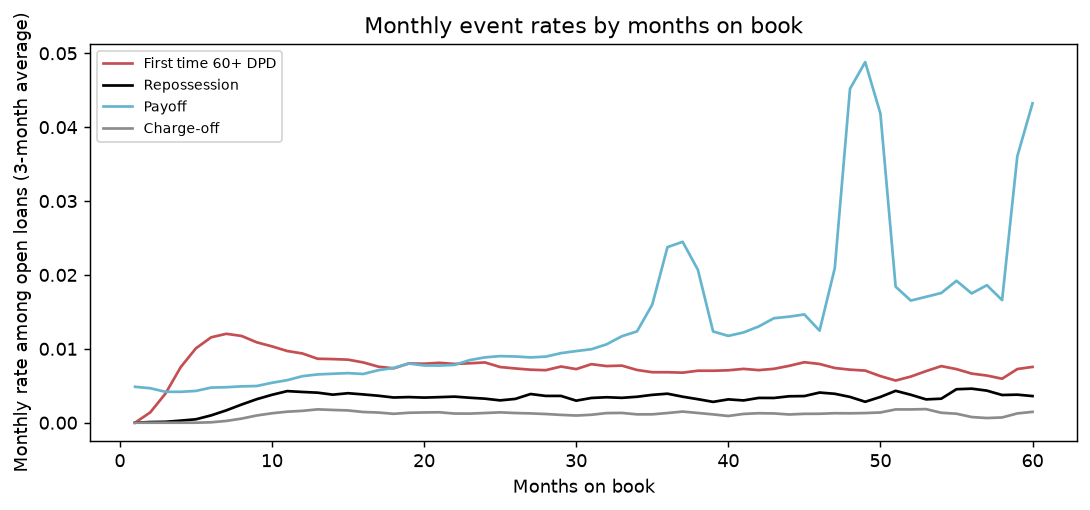

In [10]:
display(Image("figures/months_on_book_hazards.png"))

First-time serious delinquency peaks around months 6 to 8 and then eases off. Repossession follows a
few months later and then stays roughly flat. Payoff rises with age and jumps at 36, 48 and 60
months, when the shorter contracts mature. A plain Markov chain cannot see any of these age effects.

## Cures and how long delinquency lasts

end_type,episodes,charged_off,cured,paid_off,repossessed,median_months
worst_bucket,,,,,,
30-59,8588,0.0000,0.9790,0.0073,0.0136,1.0000
60-89,3152,0.0000,0.8721,0.0117,0.1161,4.0000
90+,4320,0.2243,0.2514,0.0046,0.5197,6.0000


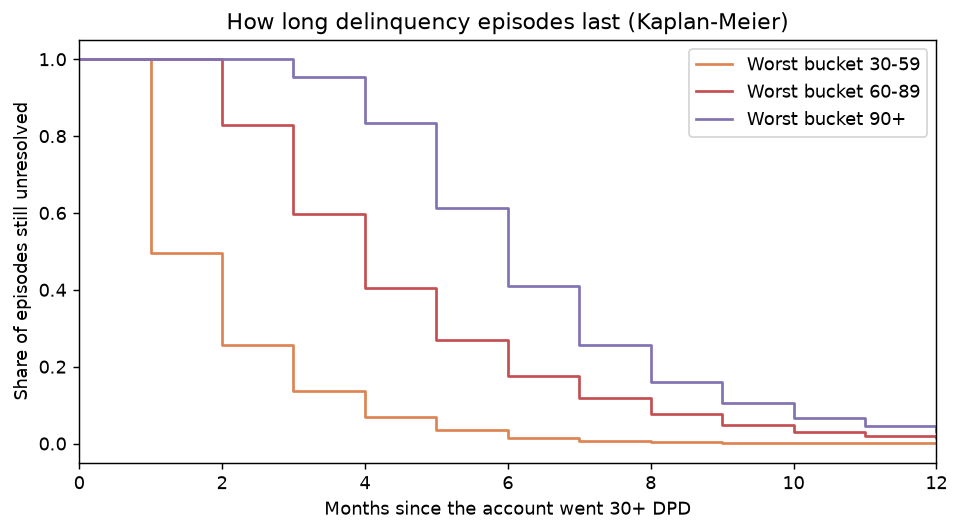

In [11]:
episodes = an.delinquency_episodes(p)
display(an.cure_rates(episodes))
display(Image("figures/delinquency_duration.png"))

Most episodes that never get past 30-59 days cure, usually within a month or two. Once an episode
reaches 90+, only about a quarter cure. Episodes still open at the end of the data are treated as
censored in the Kaplan-Meier curves, not as resolved.

## Repossession is partly a servicing outcome

,loans_reaching_60dpd,share_repossessed,share_charged_off,median_months_60dpd_to_repo
servicing_group,,,,
A,3731,0.3910,0.1136,4.0000
B,2246,0.3451,0.1358,4.0000
C,1439,0.2696,0.1668,5.0000


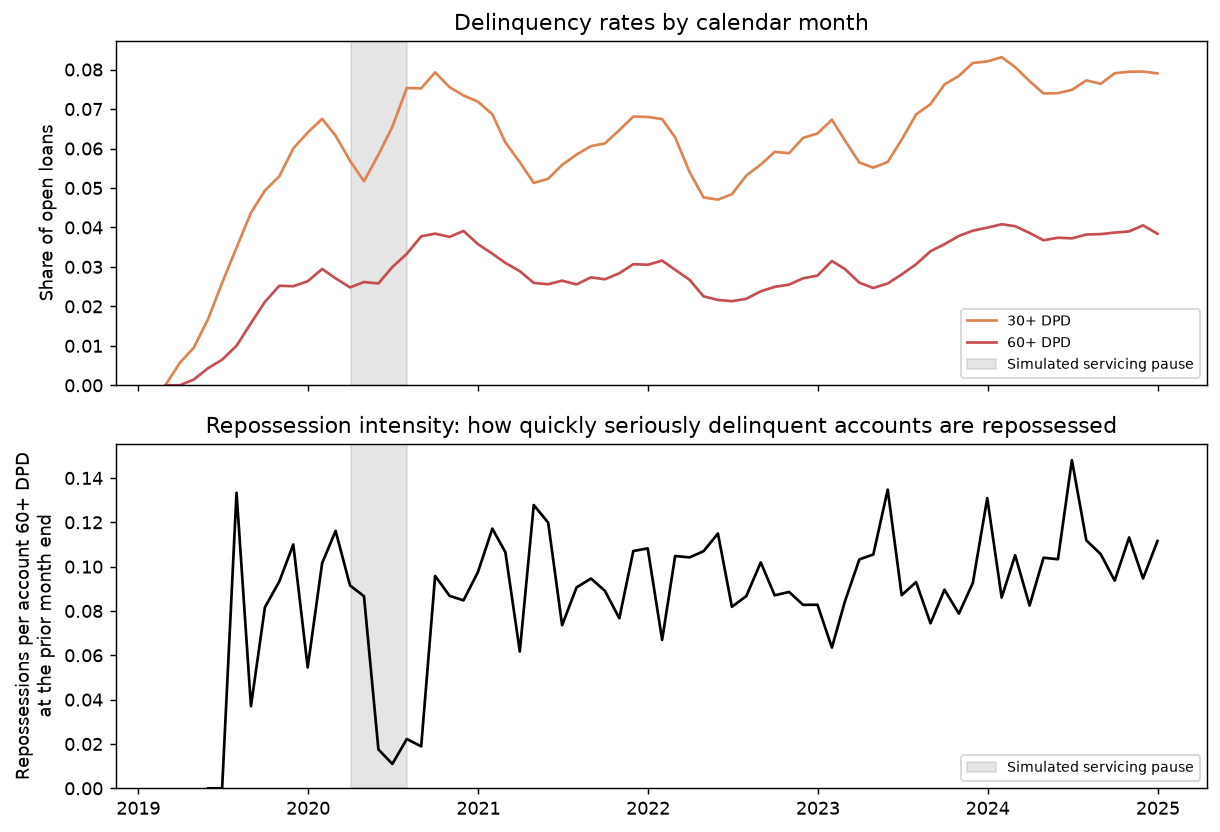

In [12]:
display(an.time_to_repossession(p))
display(Image("figures/monthly_trends.png"))

Servicing groups A, B and C get the same mix of borrowers. They differ only in how quickly they
assign accounts for repossession. Group A repossesses 39% of loans that reach 60+ days past due,
group C only 27%, and C charges more off instead.

This is the main caveat for the modeling notebook. A repossession model learns "how likely is this
servicer to repossess this account under the policies in the data". Change the policy and the
model is wrong, even if borrowers behave the same way.